# Modelado no supervisado: perfiles musicales en Spotify

## Objetivo
Este notebook identifica grupos de canciones con perfiles de audio similares, sin utilizar `popularity` ni otra etiqueta objetivo. A diferencia del aprendizaje supervisado, que predice popularidad o su categoría, aquí se busca describir estructuras naturales del catálogo que puedan servir para exploración, recomendación o segmentación musical.

## 1. Carga y preparación reproducible

Se reutilizan las decisiones de limpieza del EDA: quitar duplicados exactos y completar los tres textos faltantes. El análisis de clustering no requiere los identificadores ni los textos. Se seleccionan ocho atributos de audio: `danceability`, `energy`, `valence`, `acousticness`, `instrumentalness`, `speechiness`, `liveness` y `tempo`. Representan ritmo/bailabilidad, intensidad, carácter afectivo, cualidad acústica, contenido instrumental o hablado, presencia en vivo y velocidad. Se excluyen identificadores, género y popularidad para que no definan artificialmente la distancia entre canciones.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

def find_project_root():
    for start in [Path.cwd(), *Path.cwd().parents]:
        if (start / "Data" / "spotify-tracks-dataset-detailed.csv").exists():
            return start
    raise FileNotFoundError("No se encontró Data/spotify-tracks-dataset-detailed.csv")

DATA_PATH = find_project_root() / "Data" / "spotify-tracks-dataset-detailed.csv"
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.drop_duplicates().copy()
for column in ["artists", "album_name", "track_name"]:
    df[column] = df[column].fillna("Desconocido")
print(f"Ruta utilizada: {DATA_PATH}")
print(f"Filas originales: {len(df_raw):,}; filas tras quitar duplicados: {len(df):,}")

Ruta utilizada: /Users/stefaniafrancini/DataSciense-Curso/Data/spotify-tracks-dataset-detailed.csv
Filas originales: 114,000; filas tras quitar duplicados: 113,550


In [2]:
cluster_features = [
    "danceability", "energy", "valence", "acousticness",
    "instrumentalness", "speechiness", "liveness", "tempo",
]
missing_features = set(cluster_features) - set(df.columns)
if missing_features:
    raise ValueError(f"Faltan variables necesarias: {sorted(missing_features)}")

feature_data = df[cluster_features].copy()
print("Valores faltantes por variable:")
display(feature_data.isna().sum().rename("faltantes").to_frame())
display(feature_data.describe().T[["mean", "std", "min", "max"]])

# Los valores extremos se inspeccionan, pero no se eliminan automáticamente: pueden ser canciones válidas.
q1, q3 = feature_data.quantile(.25), feature_data.quantile(.75)
iqr = q3 - q1
outlier_counts = ((feature_data.lt(q1 - 1.5 * iqr)) | (feature_data.gt(q3 + 1.5 * iqr))).sum()
display(outlier_counts.rename("posibles_atipicos_IQR").to_frame())

Valores faltantes por variable:


,faltantes
danceability,0
energy,0
valence,0
acousticness,0
instrumentalness,0
speechiness,0
liveness,0
tempo,0


,mean,std,min,max
danceability,0.567031,0.173408,0.0,0.985
energy,0.642090,0.251052,0.0,1.000
valence,0.474207,0.259204,0.0,0.995
acousticness,0.314067,0.331907,0.0,0.996
instrumentalness,0.155702,0.309216,0.0,1.000
speechiness,0.084674,0.105761,0.0,0.965
liveness,0.213611,0.190461,0.0,1.000
tempo,122.175888,29.972861,0.0,243.372


,posibles_atipicos_IQR
danceability,615
energy,0
valence,0
acousticness,0
instrumentalness,25131
speechiness,13167
liveness,8610
tempo,615


## 2. Escalado

K-Means minimiza distancias euclidianas. Sin escalar, `tempo` (medido aproximadamente entre 0 y 250) dominaría a las variables acotadas entre 0 y 1. Se imputan eventuales faltantes con la mediana y luego se aplica `StandardScaler`; ambos ajustes se calculan únicamente sobre las variables destinadas al clustering.

In [3]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_imputed = imputer.fit_transform(feature_data)
X_scaled = scaler.fit_transform(X_imputed)
print("Media por variable (escalada):", np.round(X_scaled.mean(axis=0), 3))
print("Desvío estándar por variable (escalada):", np.round(X_scaled.std(axis=0), 3))

Media por variable (escalada): [-0. -0.  0.  0. -0. -0. -0. -0.]
Desvío estándar por variable (escalada): [1. 1. 1. 1. 1. 1. 1. 1.]


## 3. Selección de cantidad de clusters

K-Means asigna cada canción al centroide más cercano y actualiza los centroides hasta estabilizar la suma de distancias cuadradas interna (inercia). Se evalúan valores de *k* entre 2 y 8. El método del codo busca un punto de rendimientos decrecientes de la inercia; el silhouette score compara cohesión interna y separación externa (más alto es mejor). Para que el cálculo sea ágil y reproducible, el silhouette se estima sobre una muestra aleatoria de hasta 10.000 canciones; la inercia y el modelo final usan todos los registros.

,k,inercia,silhouette_muestra
0,2,735207.430713,0.227126
1,3,645859.429936,0.177864
2,4,576136.336864,0.185446
3,5,526013.927594,0.195173
4,6,478115.049056,0.202216
5,7,432739.107272,0.207479
6,8,404455.556636,0.211384


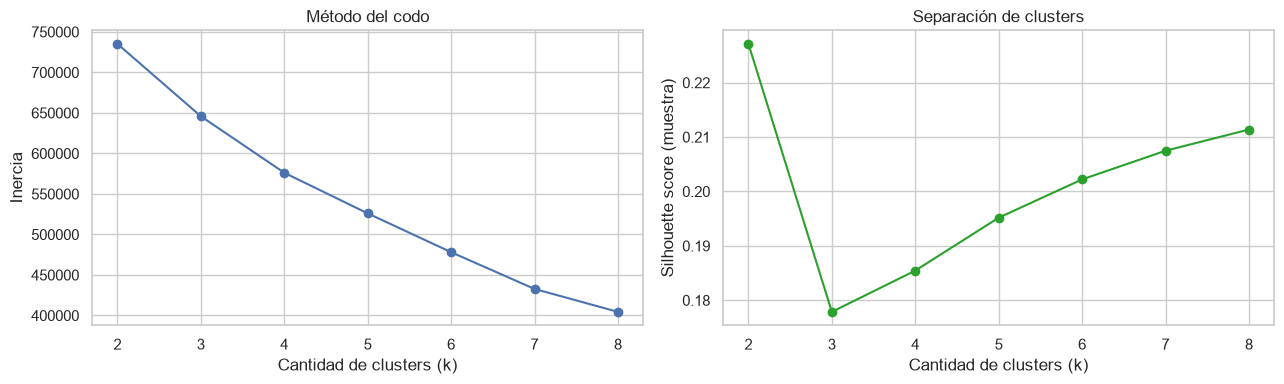

In [4]:
k_values = range(2, 9)
sample_size = min(10_000, len(X_scaled))
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_scaled), size=sample_size, replace=False)
X_silhouette = X_scaled[sample_idx]

selection_rows = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    selection_rows.append({
        "k": k,
        "inercia": model.inertia_,
        "silhouette_muestra": silhouette_score(X_silhouette, labels[sample_idx]),
    })
selection = pd.DataFrame(selection_rows)
display(selection)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(selection["k"], selection["inercia"], marker="o")
axes[0].set(title="Método del codo", xlabel="Cantidad de clusters (k)", ylabel="Inercia")
axes[1].plot(selection["k"], selection["silhouette_muestra"], marker="o", color="tab:green")
axes[1].set(title="Separación de clusters", xlabel="Cantidad de clusters (k)", ylabel="Silhouette score (muestra)")
plt.tight_layout(); plt.show()

## 4. Modelo final y evaluación

Se elige el valor de *k* con el mayor silhouette score de la grilla evaluada. Esta regla explícita evita seleccionar un número arbitrariamente; el gráfico del codo permite además verificar que la mejora de inercia sea razonable. La evaluación reporta la inercia, silhouette y tamaño de cada grupo. Un silhouette moderado es esperable en características musicales continuas: los perfiles pueden solaparse y no constituyen etiquetas verdaderas.

k seleccionado: 2
Inercia final: 735,207.10
Silhouette (muestra de 10,000 canciones): 0.227


,canciones,porcentaje
cluster,,
0,82559,72.71
1,30991,27.29


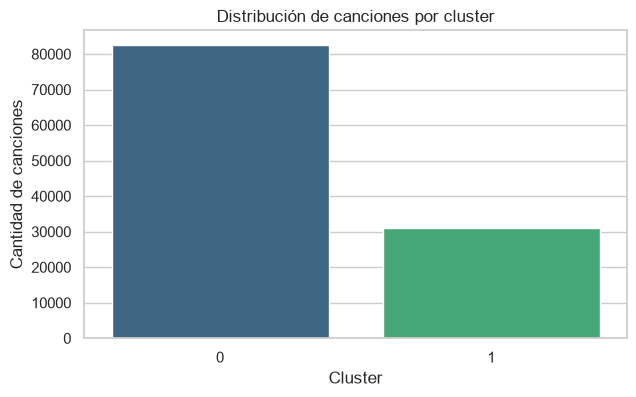

In [5]:
selected_k = int(selection.loc[selection["silhouette_muestra"].idxmax(), "k"])
kmeans = KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=20)
df["cluster"] = kmeans.fit_predict(X_scaled)
final_silhouette = silhouette_score(X_silhouette, kmeans.labels_[sample_idx])
cluster_sizes = df["cluster"].value_counts().sort_index().rename_axis("cluster").rename("canciones").to_frame()
cluster_sizes["porcentaje"] = (cluster_sizes["canciones"] / len(df) * 100).round(2)
print(f"k seleccionado: {selected_k}")
print(f"Inercia final: {kmeans.inertia_:,.2f}")
print(f"Silhouette (muestra de {sample_size:,} canciones): {final_silhouette:.3f}")
display(cluster_sizes)

plt.figure(figsize=(7, 4))
sns.barplot(data=cluster_sizes.reset_index(), x="cluster", y="canciones", hue="cluster", palette="viridis", legend=False)
plt.title("Distribución de canciones por cluster")
plt.xlabel("Cluster"); plt.ylabel("Cantidad de canciones"); plt.show()

## 5. Visualización e interpretación

PCA proyecta las ocho variables escaladas en dos componentes para visualizar los grupos; es una representación, no el espacio completo usado por K-Means. Para interpretar los perfiles, se comparan las medias originales de cada característica. El perfil se etiqueta con los dos atributos cuyo promedio estandarizado es más alto y los dos más bajos respecto del total; los nombres son descriptivos y no sustituyen la tabla de valores.

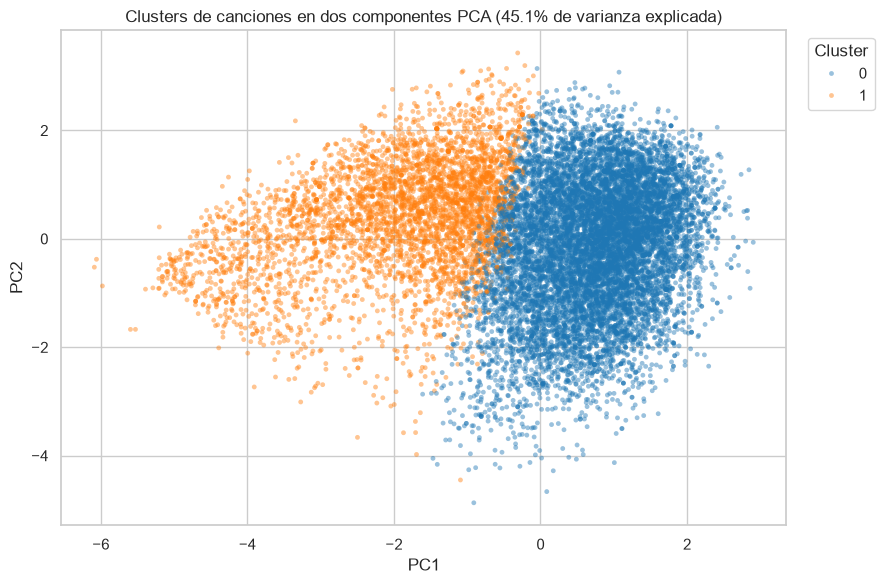

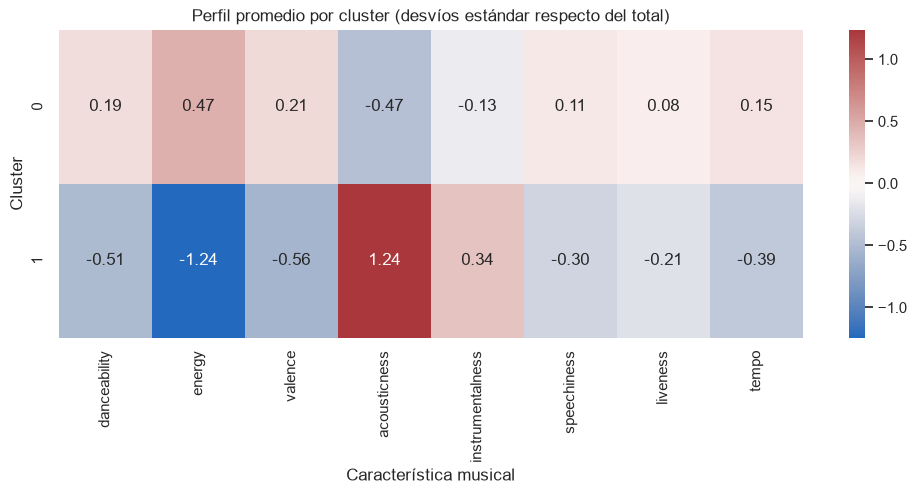

,danceability,energy,valence,acousticness,instrumentalness,speechiness,liveness,tempo
cluster,,,,,,,,
0,0.600,0.759,0.529,0.160,0.116,0.097,0.229,126.584
1,0.479,0.330,0.329,0.725,0.262,0.052,0.174,110.432


In [6]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
components = pca.fit_transform(X_scaled)
plot_df = pd.DataFrame({"PC1": components[:, 0], "PC2": components[:, 1], "cluster": df["cluster"].astype(str)})
plot_sample = plot_df.sample(min(15_000, len(plot_df)), random_state=RANDOM_STATE)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_sample, x="PC1", y="PC2", hue="cluster", palette="tab10", alpha=.45, s=12, linewidth=0)
plt.title(f"Clusters de canciones en dos componentes PCA ({pca.explained_variance_ratio_.sum():.1%} de varianza explicada)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

profile_means = df.groupby("cluster")[cluster_features].mean()
standardized_profiles = (profile_means - feature_data.mean()) / feature_data.std()
plt.figure(figsize=(12, max(4, selected_k * .8)))
sns.heatmap(standardized_profiles, cmap="vlag", center=0, annot=True, fmt=".2f")
plt.title("Perfil promedio por cluster (desvíos estándar respecto del total)")
plt.xlabel("Característica musical"); plt.ylabel("Cluster"); plt.show()
display(profile_means.round(3))

In [7]:
profile_labels = {}
for cluster, values in standardized_profiles.iterrows():
    high = ", ".join(values.nlargest(2).index)
    low = ", ".join(values.nsmallest(2).index)
    profile_labels[cluster] = f"alto en {high}; bajo en {low}"
profiles = cluster_sizes.join(pd.Series(profile_labels, name="perfil_descriptivo"))
display(profiles)

print("Conclusiones")
print(f"El catálogo se segmentó en {selected_k} perfiles basados exclusivamente en atributos de audio.")
print("Los perfiles se interpretan con las medias y el mapa de calor anteriores, no como géneros ni niveles de popularidad.")
print("Limitaciones: K-Means favorece grupos aproximadamente esféricos, los resultados dependen de las variables y de k, y PCA reduce información al visualizar.")
print("Posibles extensiones: contrastar con otros algoritmos, incorporar letras o embeddings y usar los perfiles como insumo de recomendación.")

,canciones,porcentaje,perfil_descriptivo
cluster,,,
0,82559,72.71,"alto en energy, valence; bajo en acousticness,..."
1,30991,27.29,"alto en acousticness, instrumentalness; bajo e..."


Conclusiones
El catálogo se segmentó en 2 perfiles basados exclusivamente en atributos de audio.
Los perfiles se interpretan con las medias y el mapa de calor anteriores, no como géneros ni niveles de popularidad.
Limitaciones: K-Means favorece grupos aproximadamente esféricos, los resultados dependen de las variables y de k, y PCA reduce información al visualizar.
Posibles extensiones: contrastar con otros algoritmos, incorporar letras o embeddings y usar los perfiles como insumo de recomendación.
